In [81]:
import pandas as pd

In [82]:
df=pd.read_csv('transactions.csv')

In [83]:
df.head()

,CustomerID,InvoiceDate,Product,Category,Quantity,UnitPrice
0,C0447,2025-12-11,Cookware Set,Home,1,118.36
1,C0220,2025-09-07,Smartphone,Electronics,1,476.92
2,C0253,2025-12-22,Headphones,Electronics,1,90.78
3,C0409,2025-10-23,Books,Books,1,21.54
4,C0312,2026-08-03,Notebook,Books,1,11.70


In [84]:
df.shape

(5020, 6)

In [85]:
df.columns

Index(['CustomerID', 'InvoiceDate', 'Product', 'Category', 'Quantity',
       'UnitPrice'],
      dtype='str')

In [86]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5020 entries, 0 to 5019
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CustomerID   5015 non-null   str    
 1   InvoiceDate  5020 non-null   str    
 2   Product      5020 non-null   str    
 3   Category     5020 non-null   str    
 4   Quantity     5020 non-null   int64  
 5   UnitPrice    5015 non-null   float64
dtypes: float64(1), int64(1), str(4)
memory usage: 235.4 KB


In [87]:
df.isnull().sum()

CustomerID     5
InvoiceDate    0
Product        0
Category       0
Quantity       0
UnitPrice      5
dtype: int64

In [88]:
df.describe()

,Quantity,UnitPrice
count,5020.000000,5015.000000
mean,1.690637,152.688752
std,0.865601,204.075897
min,-1.000000,-10.000000
25%,1.000000,27.205000
50%,1.000000,74.590000
75%,2.000000,116.330000
max,4.000000,812.120000


In [89]:
clean_df=df.copy()

In [90]:
clean_df=clean_df.drop_duplicates()

In [91]:
print("rows after removing duplicates:",len(clean_df))

rows after removing duplicates: 5000


In [92]:
print("rows after removing duplicates:",len(clean_df),len(df))

rows after removing duplicates: 5000 5020


In [93]:
clean_df["InvoiceDate"]=pd.to_datetime(clean_df["InvoiceDate"],errors="coerce")
print(clean_df["InvoiceDate"].dtype)

datetime64[us]


In [94]:
print(clean_df.isnull().sum())

CustomerID     5
InvoiceDate    0
Product        0
Category       0
Quantity       0
UnitPrice      5
dtype: int64


In [95]:
clean_df=clean_df.dropna(subset=["CustomerID","UnitPrice"])

In [96]:
print(clean_df.isnull().sum())

CustomerID     0
InvoiceDate    0
Product        0
Category       0
Quantity       0
UnitPrice      0
dtype: int64


In [97]:
clean_df=clean_df[(clean_df["Quantity"]>0) & (clean_df["UnitPrice"]>0)]

In [98]:
clean_df.info()

<class 'pandas.DataFrame'>
Index: 4980 entries, 0 to 4999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   CustomerID   4980 non-null   str           
 1   InvoiceDate  4980 non-null   datetime64[us]
 2   Product      4980 non-null   str           
 3   Category     4980 non-null   str           
 4   Quantity     4980 non-null   int64         
 5   UnitPrice    4980 non-null   float64       
dtypes: datetime64[us](1), float64(1), int64(1), str(3)
memory usage: 272.3 KB


In [99]:
print(clean_df[(clean_df["Quantity"]==0) | (clean_df["UnitPrice"]==0)])

Empty DataFrame
Columns: [CustomerID, InvoiceDate, Product, Category, Quantity, UnitPrice]
Index: []


In [100]:
clean_df["TotalAmount"]=(clean_df["Quantity"]*clean_df["UnitPrice"])

In [101]:
print(clean_df["TotalAmount"])

0       118.36
1       476.92
2        90.78
3        21.54
4        11.70
         ...  
4995    344.85
4996     94.81
4997     53.64
4998    114.65
4999     47.44
Name: TotalAmount, Length: 4980, dtype: float64


In [102]:
print(clean_df.head())

print("\nShape:",clean_df.shape)

print("\nMissing Values:",clean_df.isnull().sum())

print("\nSummary:",clean_df.describe())

  CustomerID InvoiceDate       Product     Category  Quantity  UnitPrice  \
0      C0447  2025-12-11  Cookware Set         Home         1     118.36   
1      C0220  2025-09-07    Smartphone  Electronics         1     476.92   
2      C0253  2025-12-22    Headphones  Electronics         1      90.78   
3      C0409  2025-10-23         Books        Books         1      21.54   
4      C0312  2026-08-03      Notebook        Books         1      11.70   

   TotalAmount  
0       118.36  
1       476.92  
2        90.78  
3        21.54  
4        11.70  

Shape: (4980, 7)

Missing Values: CustomerID     0
InvoiceDate    0
Product        0
Category       0
Quantity       0
UnitPrice      0
TotalAmount    0
dtype: int64

Summary:                       InvoiceDate     Quantity    UnitPrice  TotalAmount
count                        4980  4980.000000  4980.000000  4980.000000
mean   2026-05-15 02:21:41.204819     1.692369   152.508420   268.021384
min           2025-09-02 00:00:00     1.00000

In [103]:
clean_df.to_csv("cleaned_transactions.csv",index=False)

In [104]:
#we want to know basic size of our cleaned dataset

print("Number of Transactions:",len(clean_df))
print("Number of unique customers:",clean_df["CustomerID"].nunique())
print("Total Revenue:",clean_df["TotalAmount"].sum())
print("Average transaction values:",clean_df["TotalAmount"].mean())

Number of Transactions: 4980
Number of unique customers: 500
Total Revenue: 1334746.49
Average transaction values: 268.02138353413653


In [105]:
#this tells us how many transactions belong to each product category 
print(clean_df["Category"].value_counts())

Category
Books          1307
Electronics    1298
Home           1194
Fashion        1181
Name: count, dtype: int64


In [106]:
#this tells which product appear most frequenty in our transactions 
print(clean_df["Product"].value_counts().head(10))

Product
Books           455
Laptop          452
Smartphone      441
Notebook        432
Coffee Maker    430
Novel           420
Shoes           407
Headphones      405
Backpack        402
Cookware Set    387
Name: count, dtype: int64


In [107]:
#need a fixed reference date--to cal how many days have passed since each customer's last purchase

analysis_date=clean_df["InvoiceDate"].max()+pd.Timedelta(days=1)

print("Analysis Date : ", analysis_date)
print("Analysis Date : ", analysis_date.date())

Analysis Date :  2026-09-02 00:00:00
Analysis Date :  2026-09-02


In [ ]:
# calculating RECENCY , FREQUENCY , Monetary
rfm=clean_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate",lambda x: (analysis_date - x.max()).days),
    Frequency = ("InvoiceDate","count"),
    Monetary = ("TotalAmount","sum")
).reset_index()

In [109]:
type(rfm)

pandas.DataFrame

In [110]:
rfm.head()

,CustomerID,Recency,Frequency,Monetory
0,C0001,15,9,932.34
1,C0002,193,4,714.51
2,C0003,49,8,856.02
3,C0004,34,7,1477.69
4,C0005,2,9,1664.66


In [111]:
rfm.describe()

,Recency,Frequency,Monetory
count,500.000000,500.000000,500.000000
mean,48.252000,9.960000,2669.492980
std,54.886406,3.127613,1972.970032
min,1.000000,1.000000,224.450000
25%,7.000000,8.000000,1329.860000
50%,26.000000,10.000000,2171.980000
75%,66.250000,12.000000,3431.427500
max,212.000000,23.000000,14844.880000


In [112]:
print(rfm.isnull().sum())

CustomerID    0
Recency       0
Frequency     0
Monetory      0
dtype: int64


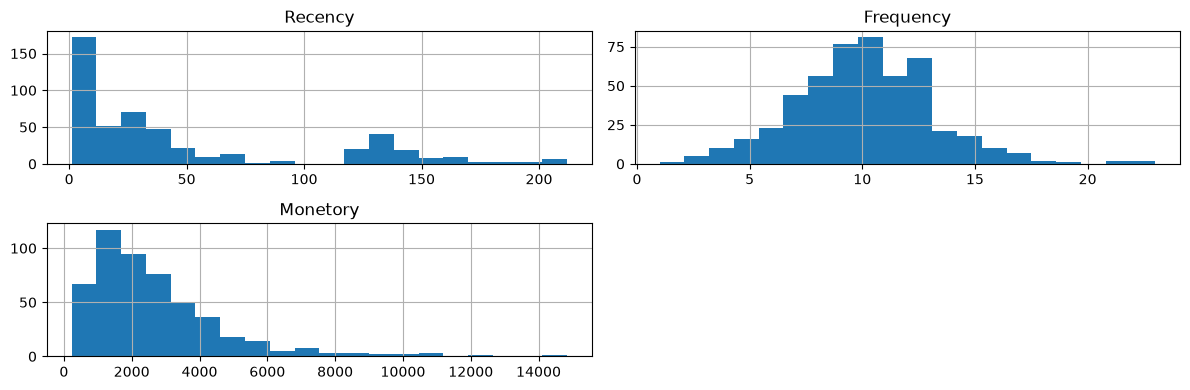

In [ ]:
import matplotlib.pyplot as plt

#why : to check RFM values' distribution 

rfm[["Recency","Frequency","Monetary"]].hist(
    bins=20,
    figsize=(12,4)
)

plt.tight_layout()
plt.show()

In [ ]:
# checking skewness -- 0:properly skewed , neg : left skewed , positive : right skewed 
print(rfm[["Recency","Frequency","Monetary"]].skew())

Recency      1.196207
Frequency    0.556497
Monetory     2.010562
dtype: float64


In [ ]:
import numpy as np 

# skewness to compress values 
rfm_log = rfm.copy()

rfm_log[["Recency","Frequency","Monetary"]]=np.log1p(
    rfm_log[["Recency","Frequency","Monetary"]]
)

-how log1p(x) help in skewness?

- Definition: log1p(x) means log of (1 + x).
- Formula:log1p(x) = log(1 + x)
- Example:log1p(9) = log(10) ≈ 2.303
- Purpose: It compresses large values, reducing the effect of very large numbers.
- Why useful in our project: RFM data, especially Monetary, is right-skewed, so log1p() helps make the distribution more balanced.
- Advantage: It also safely handles x = 0:log1p(0) = log(1) = 0
  while log(0) is undefined.
Memory trick:  
log1p(x) = log of 1 plus x.

In [116]:
rfm_log.head()

,CustomerID,Recency,Frequency,Monetory
0,C0001,2.772589,2.302585,6.838770
1,C0002,5.267858,1.609438,6.572996
2,C0003,3.912023,2.197225,6.753461
3,C0004,3.555348,2.079442,7.298912
4,C0005,1.098612,2.302585,7.417977


In [117]:
rfm.head()

,CustomerID,Recency,Frequency,Monetory
0,C0001,15,9,932.34
1,C0002,193,4,714.51
2,C0003,49,8,856.02
3,C0004,34,7,1477.69
4,C0005,2,9,1664.66


In [ ]:
# checking if skewness really reduced 
print(rfm_log[["Recency","Frequency","Monetary"]].skew())

Recency     -0.192666
Frequency   -0.750757
Monetory    -0.198395
dtype: float64


In [119]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [120]:
#scaling rfm_log becuase k-means is distance based 

from sklearn.preprocessing import StandardScaler



#Scaling : main purpose = to prevent the any feature from K-Means' distance calculation being dominated by greater numbers 



LOGGING
:
"to fix shape/distribution of data "



SCALING
:
"to fix measurement scale of features"

➡️ Learn the scale of the three RFM features and transform them to a standardized scale

In [ ]:
# creating the scaler that will standardize our RFM features
scaler = StandardScaler()

# scale RFM features so K-Means can compare then fairly
rfm_scaled=scaler.fit_transform(
    rfm_log[["Recency","Frequency","Monetary"]]
)


In [122]:
# check scaled values 
print(rfm_scaled[:5])

[[-0.25813717 -0.16183347 -1.14500539]
 [ 1.555691   -2.45726203 -1.51992948]
 [ 0.57012529 -0.51074572 -1.26534875]
 [ 0.31085587 -0.90079642 -0.49588828]
 [-1.47496192 -0.16183347 -0.32792491]]


In [123]:
# check shape of our scaled values 
print(rfm_scaled.shape)

(500, 3)


In [124]:
# verifying that each scaled feature has mean close to 0 
print(rfm_scaled.mean(axis=0)) 

# verifying each scaled feature has standard deviation = 1
print(rfm_scaled.std(axis=0))

[-3.30402372e-16 -8.88178420e-18 -1.53654867e-16]
[1. 1. 1.]


#axis tell numpy which direction to cal,here col wise 

axis = 0 : down : columns 

axis = 1 : across : rows

# elbow method 


In [125]:
from sklearn.cluster import KMeans

inertia =[]

# to test different num of clusters 

for k in range(2,9):
    kmeans=KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

print(inertia)

[930.864510056982, 686.6585536100024, 582.8301683536193, 489.9295139538596, 441.74054206330385, 401.42378109740486, 372.0325772373078]


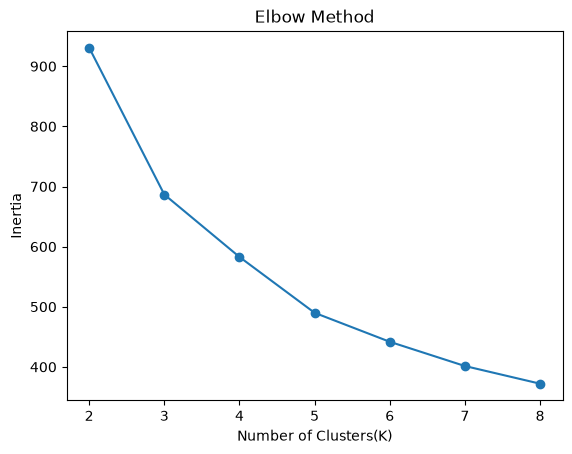

In [126]:
import matplotlib.pyplot as plt

#creating k-values corresponding to the inertia values 
k_values=range(2,9)

#plotting how inertia changes as the number of clusters increases
plt.plot(k_values,inertia,marker="o")

plt.xlabel("Number of Clusters(K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")

plt.show()

In [132]:
from sklearn.metrics import silhouette_score

silhouette_scores = []


for k in range(2, 9):

    # Why: Create K-Means model for the current K
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Why: Create clusters using scaled RFM data
    labels = kmeans.fit_predict(rfm_scaled)

    # Why: Measure how well-separated the clusters are
    score = silhouette_score(rfm_scaled, labels)

    # Why: Save the score for this K
    silhouette_scores.append(score)

print(silhouette_scores)

[0.33492829468140006, 0.31188100798066976, 0.284606491586937, 0.2765819796461843, 0.2634213442334171, 0.26241156649344094, 0.270013698390676]


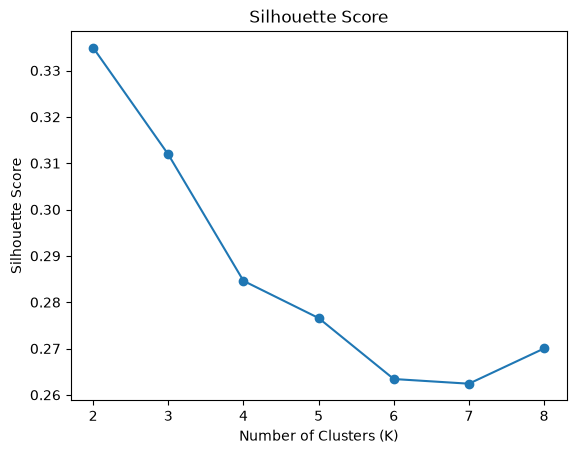

In [133]:
import matplotlib.pyplot as plt

k_values = range(2, 9)

# Why: Plot silhouette score for each number of clusters
plt.plot(k_values, silhouette_scores, marker="o")

# Why: Label the axes
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

# Why: Give the graph a clear title
plt.title("Silhouette Score")

# Why: Show the graph
plt.show()

In [ ]:
# Why: Compare the RFM profiles produced by different K values

for k in [2, 4, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    temp_rfm = rfm.copy()
    temp_rfm["Cluster"] = labels

    print("\nK =", k)
    print(temp_rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean())


K = 2
           Recency  Frequency     Monetory
Cluster                                   
0        84.722944   8.606061  1360.170303
1        16.933086  11.122677  3793.855576

K = 4
           Recency  Frequency     Monetory
Cluster                                   
0         6.504425   8.539823  3030.868496
1        77.989130  11.326087  2210.648859
2         7.284091  13.159091  5354.313977
3        73.043478   6.721739   994.081130

K = 5
           Recency  Frequency     Monetory
Cluster                                   
0        59.886364   4.818182   875.038182
1         5.707317  12.865854  5578.856585
2        91.875000   8.828125  1237.400312
3         6.603604   8.486486  2924.944234
4        63.185185  12.155556  2634.981630


In [136]:
# Why: Check whether clusters have reasonable numbers of customers

for k in [4, 5]:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    print("\nK =", k)
    print(pd.Series(labels).value_counts().sort_index())


K = 4
0    113
1    184
2     88
3    115
Name: count, dtype: int64

K = 5
0     44
1     82
2    128
3    111
4    135
Name: count, dtype: int64



K = 4
           Recency  Frequency     Monetory
Cluster                                   
0         6.504425   8.539823  3030.868496
1        77.989130  11.326087  2210.648859
2         7.284091  13.159091  5354.313977
3        73.043478   6.721739   994.081130


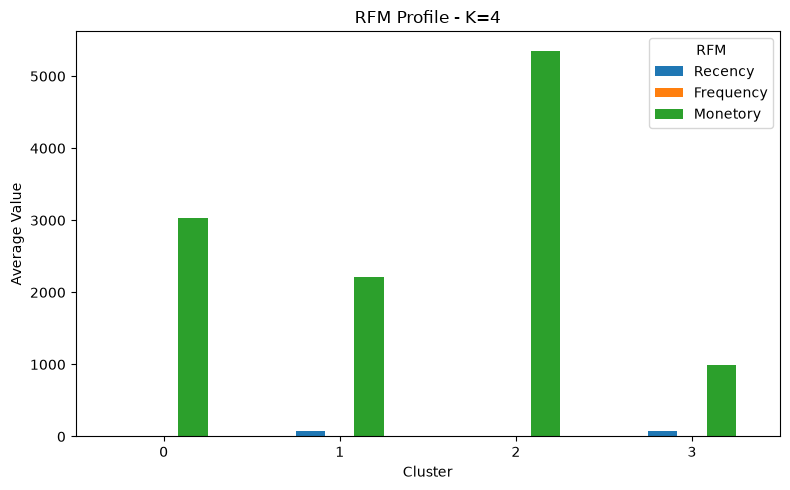


K = 5
           Recency  Frequency     Monetory
Cluster                                   
0        59.886364   4.818182   875.038182
1         5.707317  12.865854  5578.856585
2        91.875000   8.828125  1237.400312
3         6.603604   8.486486  2924.944234
4        63.185185  12.155556  2634.981630


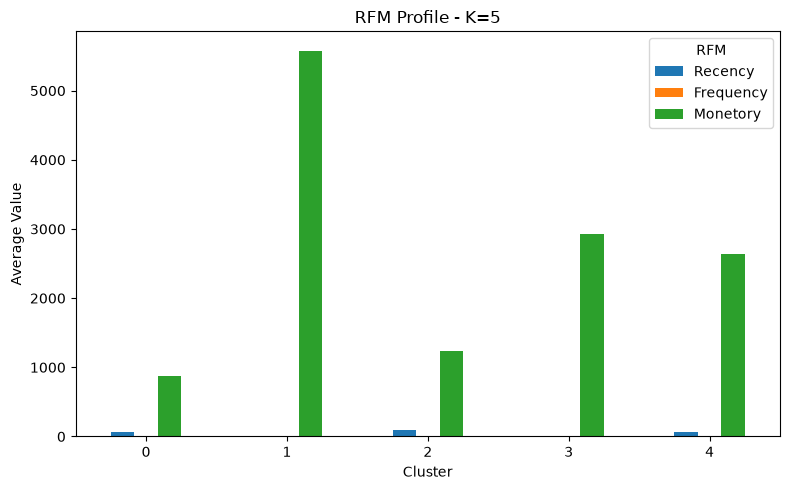

In [ ]:
import matplotlib.pyplot as plt

# Why: Compare the cluster profiles for K=4 and K=5
for k in [4, 5]:

    # Why: Create K-Means model
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Why: Assign every customer to a cluster
    labels = kmeans.fit_predict(rfm_scaled)

    # Why: Keep the original RFM data and add cluster labels
    temp_rfm = rfm.copy()
    temp_rfm["Cluster"] = labels

    # Why: Calculate average RFM values for each cluster
    profile = temp_rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean()

    print("\nK =", k)
    print(profile)

    # Why: Visualize the average RFM values
    profile.plot(kind="bar", figsize=(8, 5))

    plt.title(f"RFM Profile - K={k}")
    plt.xlabel("Cluster")
    plt.ylabel("Average Value")
    plt.xticks(rotation=0)
    plt.legend(title="RFM")
    plt.tight_layout()
    plt.show()

In [140]:
from sklearn.cluster import KMeans

# Why: Use 4 clusters based on our Elbow + profile comparison
final_k = 4

# Why: Create the final K-Means model
final_kmeans = KMeans(
    n_clusters=final_k,
    random_state=42,
    n_init=10
)

# Why: Assign every customer to one of the 4 final clusters
rfm["Cluster"] = final_kmeans.fit_predict(rfm_scaled)

In [141]:
# Why: See how many customers are in each final cluster
print(rfm["Cluster"].value_counts().sort_index())

Cluster
0    113
1    184
2     88
3    115
Name: count, dtype: int64


In [142]:
print(rfm)

    CustomerID  Recency  Frequency  Monetory  Cluster
0        C0001       15          9    932.34        3
1        C0002      193          4    714.51        3
2        C0003       49          8    856.02        3
3        C0004       34          7   1477.69        3
4        C0005        2          9   1664.66        0
..         ...      ...        ...       ...      ...
495      C0496        9         11   3177.73        2
496      C0497       29          5    735.89        3
497      C0498        2         13   5467.72        2
498      C0499      133         11   2429.57        1
499      C0500      149          9    486.66        3

[500 rows x 5 columns]


In [ ]:
# Why: Calculate the average RFM behavior of each final cluster
cluster_profile = rfm.groupby("Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean()

print(cluster_profile)

           Recency  Frequency     Monetory
Cluster                                   
0         6.504425   8.539823  3030.868496
1        77.989130  11.326087  2210.648859
2         7.284091  13.159091  5354.313977
3        73.043478   6.721739   994.081130


In [147]:
# Why: Map each K-Means cluster to a meaningful business segment name
segment_names = {
    0: "Recent High-Value Customers",
    1: "At-Risk Loyal Customers",
    2: "VIP High-Value Customers",
    3: "Low-Engagement Customers"
}

# Why: Convert cluster numbers into readable segment names
rfm["Segment"] = rfm["Cluster"].map(segment_names)

# Why: Check the result
print(rfm.head())

  CustomerID  Recency  Frequency  Monetory  Cluster  \
0      C0001       15          9    932.34        3   
1      C0002      193          4    714.51        3   
2      C0003       49          8    856.02        3   
3      C0004       34          7   1477.69        3   
4      C0005        2          9   1664.66        0   

                       Segment  
0     Low-Engagement Customers  
1     Low-Engagement Customers  
2     Low-Engagement Customers  
3     Low-Engagement Customers  
4  Recent High-Value Customers  


In [148]:
# Why: Give each customer segment a suitable marketing strategy
recommendations = {
    "Recent High-Value Customers":
        "Offer loyalty rewards and personalized product recommendations.",

    "At-Risk Loyal Customers":
        "Send re-engagement offers and personalized discounts to encourage a return.",

    "VIP High-Value Customers":
        "Provide exclusive offers, premium rewards, and early access to new products.",

    "Low-Engagement Customers":
        "Use targeted discounts and re-engagement campaigns to increase activity."
}

# Why: Map each segment to its marketing recommendation
rfm["Recommendation"] = rfm["Segment"].map(recommendations)

# Why: Check the final customer-level output
print(rfm.head())

  CustomerID  Recency  Frequency  Monetory  Cluster  \
0      C0001       15          9    932.34        3   
1      C0002      193          4    714.51        3   
2      C0003       49          8    856.02        3   
3      C0004       34          7   1477.69        3   
4      C0005        2          9   1664.66        0   

                       Segment  \
0     Low-Engagement Customers   
1     Low-Engagement Customers   
2     Low-Engagement Customers   
3     Low-Engagement Customers   
4  Recent High-Value Customers   

                                      Recommendation  
0  Use targeted discounts and re-engagement campa...  
1  Use targeted discounts and re-engagement campa...  
2  Use targeted discounts and re-engagement campa...  
3  Use targeted discounts and re-engagement campa...  
4  Offer loyalty rewards and personalized product...  


In [149]:
# Why: Save the final customer-level RFM segmentation results
rfm.to_csv("rfm_customer_segments.csv", index=False)